# Week 4 Lab — Logistic Regression and Classification Metrics

## Learning outcomes

By the end of this lab, you should be able to:

1. Explain how logistic regression turns a linear score into a probability.
2. Train a logistic regression model for binary classification with scikit-learn.
3. Read predicted probabilities and change the decision threshold.
4. Evaluate a classifier with a confusion matrix, precision, recall and F1.
5. Interpret the ROC curve and ROC AUC.
6. Explain why accuracy alone can be misleading.
7. Compare logistic regression with last week's perceptron.

## How this notebook is organised

| Part | Content |
|---|---|
| **Part 1 — Lab** (Sections 1–8) | Explanation + code on generated and real datasets |
| **Part 2 — Practice exercise** | Guided, in-class exercise (~30 minutes) |
| **Part 3 — Assignment** | Graded, take-home assignment (100 points) |

## Connection to last week

Last week the perceptron computed a **score** $s=\mathbf{w}^T\mathbf{x}+b$ and predicted a class from its sign. Logistic regression computes the **same kind of score**, but then converts it into a **probability**. That small change is useful: we can say *how sure* the model is, and we can decide how cautious or aggressive the model should be.

> **Label convention.** The perceptron lab used labels $-1/+1$. In this lab we use $0/1$, where $1$ is the **positive class** (the thing we are trying to find).

## Recurring classification workflow

$$
\text{inspect} \rightarrow \text{choose }X,y \rightarrow \text{split}
\rightarrow \text{fit} \rightarrow \text{predict} \rightarrow
\text{evaluate} \rightarrow \text{diagnose}
$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_wine, make_blobs, make_classification
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 100


def class_counts(y):
    """Readable class counts, e.g. {0: 357, 1: 212}."""
    values, counts = np.unique(np.asarray(y), return_counts=True)
    return {int(v): int(c) for v, c in zip(values, counts)}


print("Environment ready")

Environment ready


## 1. From a linear score to a probability

A linear classifier computes a score for every observation:

$$
z(\mathbf{x})=\mathbf{w}^{T}\mathbf{x}+b.
$$

The score can be any real number. Logistic regression converts it into a probability between 0 and 1 using the **sigmoid** function:

$$
\sigma(z)=\frac{1}{1+e^{-z}},
\qquad
P(y=1\mid \mathbf{x})=\sigma(\mathbf{w}^{T}\mathbf{x}+b).
$$

What to remember about the sigmoid:

- Output is always between 0 and 1, so it can be read as a probability.
- A score of **0** gives a probability of **0.5** (exactly on the decision boundary).
- Large positive scores give probabilities close to 1; large negative scores give probabilities close to 0.

The predicted class is then decided by a **threshold** (usually 0.5): predict class 1 if the probability is at least the threshold, otherwise class 0.

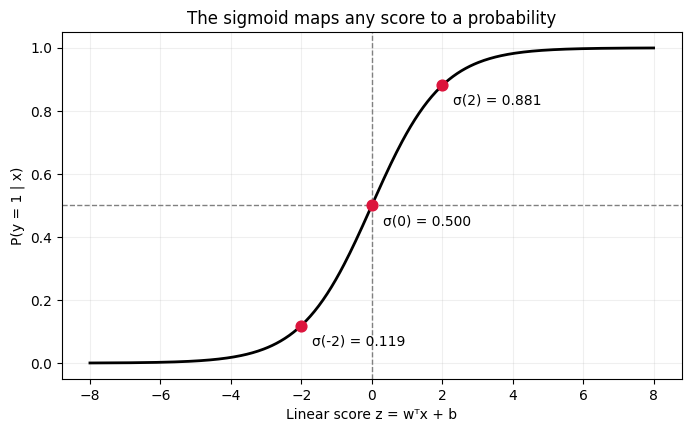

In [2]:
def sigmoid(z):
    """Convert a linear score into a probability."""
    z = np.asarray(z, dtype=float)
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


z_values = np.linspace(-8, 8, 400)

plt.figure(figsize=(8, 4.5))
plt.plot(z_values, sigmoid(z_values), color="black", linewidth=2)
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.axvline(0.0, color="gray", linestyle="--", linewidth=1)

for z0 in (-2, 0, 2):
    plt.scatter([z0], [sigmoid(z0)], color="crimson", zorder=3, s=60)
    plt.annotate(f"σ({z0}) = {sigmoid(z0):.3f}", (z0, sigmoid(z0)),
                 xytext=(8, -14), textcoords="offset points")

plt.xlabel("Linear score z = wᵀx + b")
plt.ylabel("P(y = 1 | x)")
plt.title("The sigmoid maps any score to a probability")
plt.grid(alpha=0.2)
plt.show()

In [3]:
scores = np.array([-6, -2, -1, 0, 1, 2, 6])

pd.DataFrame({
    "score z": scores,
    "probability": sigmoid(scores),
    "predicted class (threshold 0.5)": (sigmoid(scores) >= 0.5).astype(int),
})

,score z,probability,predicted class (threshold 0.5)
0,-6,0.002473,0
1,-2,0.119203,0
2,-1,0.268941,0
3,0,0.500000,1
4,1,0.731059,1
5,2,0.880797,1
6,6,0.997527,1


**Questions:**

1. What probability does a score of exactly zero produce?
2. What happens to the probability as the score becomes very large and positive? Very large and negative?
3. Last week's perceptron score was "not a probability". What does the sigmoid change?

## 2. How does the model learn? (the idea)

Training logistic regression means finding weights $\mathbf{w}$ and intercept $b$ so that the predicted probabilities agree with the true labels as well as possible. The process is:

1. Start with some weights.
2. Measure how wrong the predicted probabilities are, using a **loss**.
3. Adjust the weights to reduce the loss.
4. Repeat until the loss stops improving.

The loss used by logistic regression is called **log-loss**. You do not need the formula — only the idea:

- If the true label is 1, the loss is **small** when the predicted probability is close to 1 and **large** when it is close to 0.
- If the true label is 0, it is the other way round.
- A **confident wrong** prediction is punished much more than an unsure one.

In scikit-learn, `.fit()` carries out steps 1–4 for us. (In the assignment you will try a simple version of this search yourself.)

In [4]:
cases = pd.DataFrame({
    "true label": [1, 1, 1, 1, 0, 0],
    "predicted probability of 1": [0.99, 0.90, 0.50, 0.01, 0.10, 0.99],
    "what happened": ["confident and right", "right", "unsure",
                      "confident and WRONG", "right", "confident and WRONG"],
})

# loss = -log(p) if the true label is 1, and -log(1 - p) if it is 0
p = cases["predicted probability of 1"]
cases["loss"] = np.where(cases["true label"] == 1, -np.log(p), -np.log(1 - p))
cases

,true label,predicted probability of 1,what happened,loss
0,1,0.99,confident and right,0.010050
1,1,0.90,right,0.105361
2,1,0.50,unsure,0.693147
3,1,0.01,confident and WRONG,4.605170
4,0,0.10,right,0.105361
5,0,0.99,confident and WRONG,4.605170


**Questions:**

1. Which rows have the largest loss? Why do you think the loss is designed this way?
2. A model that always predicts probability 0.5 for everything would get which loss on every row?

## 3. Training logistic regression on a generated dataset

We generate two **overlapping** clusters. No straight line can classify every point correctly here, but logistic regression still finds a sensible boundary and tells us how confident it is.

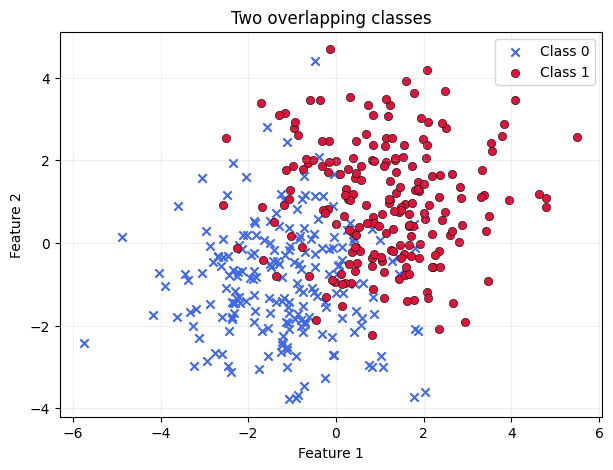

Feature-matrix shape: (400, 2)
Class counts: {0: 200, 1: 200}


In [5]:
X_toy, y_toy = make_blobs(
    n_samples=400,
    centers=[(-1.2, -1.0), (1.2, 1.0)],
    cluster_std=1.4,
    random_state=RANDOM_STATE,
)

plt.figure(figsize=(7, 5))
plt.scatter(X_toy[y_toy == 0, 0], X_toy[y_toy == 0, 1], color="royalblue",
            marker="x", label="Class 0")
plt.scatter(X_toy[y_toy == 1, 0], X_toy[y_toy == 1, 1], color="crimson",
            marker="o", edgecolor="black", linewidth=0.4, label="Class 1")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two overlapping classes")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Feature-matrix shape:", X_toy.shape)
print("Class counts:", class_counts(y_toy))

In [6]:
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    X_toy, y_toy,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_toy,
)

toy_model = LogisticRegression()
toy_model.fit(Xt_train, yt_train)

print("Weights w:", toy_model.coef_[0])
print("Intercept b:", toy_model.intercept_[0])
print("Train accuracy:", round(toy_model.score(Xt_train, yt_train), 3))
print("Test accuracy: ", round(toy_model.score(Xt_test, yt_test), 3))

Weights w: [1.412 1.119]
Intercept b: -0.0898038071025696
Train accuracy: 0.873
Test accuracy:  0.84


### Probabilities, scores and predictions

`predict_proba` returns two columns: the probability of class 0 and the probability of class 1. We keep the second one. We can also reproduce it ourselves from the learned weights: compute the score, then apply the sigmoid.

In [7]:
proba_class1 = toy_model.predict_proba(Xt_test)[:, 1]

# By hand: score = w1*x1 + w2*x2 + b, then the sigmoid
z_by_hand = Xt_test @ toy_model.coef_[0] + toy_model.intercept_[0]
proba_by_hand = sigmoid(z_by_hand)

pd.DataFrame({
    "x1": Xt_test[:6, 0],
    "x2": Xt_test[:6, 1],
    "score z": z_by_hand[:6],
    "P(class 1)": proba_class1[:6],
    "predicted": toy_model.predict(Xt_test[:6]),
    "true": yt_test[:6],
})

,x1,x2,score z,P(class 1),predicted,true
0,1.656586,-0.751559,1.409130,0.803629,1,1
1,-0.472915,1.145834,0.524092,0.628104,1,0
2,-2.262786,-0.789449,-4.168794,0.015235,0,0
3,-0.092555,-2.273142,-2.763436,0.059332,0,0
4,-1.412499,-0.176356,-2.282037,0.092622,0,0
5,-2.687225,-0.336971,-4.262076,0.013897,0,0


In [8]:
print("Our by-hand probabilities match scikit-learn:",
      np.allclose(proba_by_hand, proba_class1))

Our by-hand probabilities match scikit-learn: True


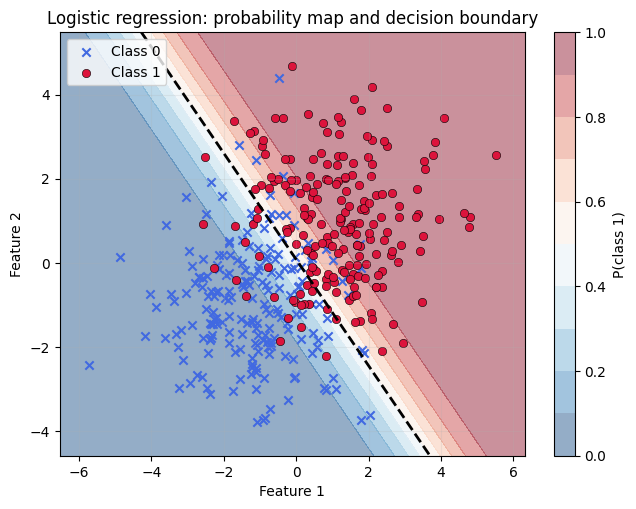

In [9]:
def plot_decision_regions(model, X, y, title, ax=None, probabilistic=True):
    """Plot a fitted 2-feature classifier: regions, 0.5 boundary and data."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7.5, 5.5))

    pad = 0.8
    x1 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300)
    x2 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300)
    xx1, xx2 = np.meshgrid(x1, x2)
    grid = np.c_[xx1.ravel(), xx2.ravel()]

    if probabilistic:
        zz = model.predict_proba(grid)[:, 1].reshape(xx1.shape)
        filled = ax.contourf(xx1, xx2, zz, levels=np.linspace(0, 1, 11),
                             cmap="RdBu_r", alpha=0.45)
        plt.colorbar(filled, ax=ax, label="P(class 1)")
        ax.contour(xx1, xx2, zz, levels=[0.5], colors="black",
                   linewidths=2, linestyles="--")
    else:
        zz = model.predict(grid).reshape(xx1.shape)
        ax.contourf(xx1, xx2, zz, levels=[-0.5, 0.5, 1.5],
                    cmap="RdBu_r", alpha=0.35)
        ax.contour(xx1, xx2, zz, levels=[0.5], colors="black",
                   linewidths=2, linestyles="--")

    ax.scatter(X[y == 0, 0], X[y == 0, 1], color="royalblue", marker="x", label="Class 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], color="crimson", marker="o",
               edgecolor="black", linewidth=0.4, label="Class 1")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.set_title(title)
    ax.legend(loc="upper left")
    ax.grid(alpha=0.2)


plot_decision_regions(toy_model, X_toy, y_toy,
                      "Logistic regression: probability map and decision boundary")
plt.show()

The dashed line is the **decision boundary**, where the probability is exactly 0.5 (score = 0). It is a straight line, just like the perceptron's. The colours add something new: the model's **confidence**, which fades smoothly from blue (probably class 0) to red (probably class 1).

**Questions:**

1. Why can't the model reach 100% accuracy on this data?
2. Where on the map is the model least certain? What probability does it give there?
3. What would the picture look like if the two clusters were much further apart?

## 4. A real dataset: Breast Cancer Wisconsin

The dataset contains 569 tumours described by 30 measurements of cell nuclei. Each tumour is **malignant** or **benign**.

scikit-learn stores `malignant = 0` and `benign = 1`. In screening, the thing we want to *find* is malignancy, so we flip the labels and make **malignant the positive class ($y=1$)**. Precision and recall are always defined relative to the positive class, so this choice matters.

In [10]:
cancer = load_breast_cancer(as_frame=True)
X_cancer = cancer.data
y_cancer = (cancer.target == 0).astype(int)      # 1 = malignant (positive class)

print("Feature-matrix shape:", X_cancer.shape)
print("Class counts (1 = malignant):", class_counts(y_cancer))
X_cancer.iloc[:, :5].head()

Feature-matrix shape: (569, 30)
Class counts (1 = malignant): {0: 357, 1: 212}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
0,17.99,10.38,122.80,1001.0,0.11840
1,20.57,17.77,132.90,1326.0,0.08474
2,19.69,21.25,130.00,1203.0,0.10960
3,11.42,20.38,77.58,386.1,0.14250
4,20.29,14.34,135.10,1297.0,0.10030


The 30 features are on very different scales (areas are in the hundreds, smoothness values are around 0.1). Logistic regression trains more reliably when features are on a similar scale, so we add a `StandardScaler` step. A **pipeline** bundles the scaler and the model, learns the scaling from the training data only, and applies it automatically to new data.

In [11]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cancer, y_cancer,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_cancer,
)

cancer_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cancer_model.fit(Xc_train, yc_train)

yc_pred = cancer_model.predict(Xc_test)                    # classes 0 / 1
yc_proba = cancer_model.predict_proba(Xc_test)[:, 1]       # P(malignant)

print("Training shape:", Xc_train.shape, " Test shape:", Xc_test.shape)
print("Test accuracy:", round(accuracy_score(yc_test, yc_pred), 3))

Training shape: (426, 30)  Test shape: (143, 30)
Test accuracy: 0.965


## 5. Evaluating a binary classifier

### 5.1 The confusion matrix

Accuracy alone does not tell us *what kind* of mistakes the model makes. The **confusion matrix** counts them. Rows are the true classes and columns are the predicted classes. With malignant as the positive class:

| | Predicted benign (0) | Predicted malignant (1) |
|---|---|---|
| **Actually benign (0)** | **TN** — true negative | **FP** — false positive (false alarm) |
| **Actually malignant (1)** | **FN** — false negative (missed case) | **TP** — true positive |

TN=89  FP=1  FN=4  TP=49


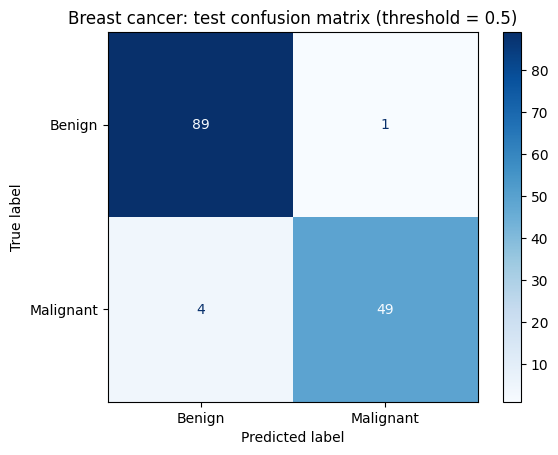

In [12]:
tn, fp, fn, tp = confusion_matrix(yc_test, yc_pred, labels=[0, 1]).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

ConfusionMatrixDisplay.from_predictions(
    yc_test, yc_pred,
    labels=[0, 1],
    display_labels=["Benign", "Malignant"],
    cmap="Blues",
)
plt.title("Breast cancer: test confusion matrix (threshold = 0.5)")
plt.show()

### 5.2 Accuracy, precision, recall and F1

| Metric | Formula | In words |
|---|---|---|
| **Accuracy** | $\dfrac{TP+TN}{\text{all}}$ | What fraction of all predictions were right? |
| **Precision** | $\dfrac{TP}{TP+FP}$ | Of the cases I flagged as positive, how many really were? |
| **Recall** | $\dfrac{TP}{TP+FN}$ | Of the real positives, how many did I catch? |
| **F1** | $\dfrac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$ | A single number that is high only when precision *and* recall are both high |

Low precision means many false alarms. Low recall means many missed cases.

In [13]:
accuracy_manual = (tp + tn) / (tp + tn + fp + fn)
precision_manual = tp / (tp + fp)
recall_manual = tp / (tp + fn)
f1_manual = 2 * precision_manual * recall_manual / (precision_manual + recall_manual)

pd.DataFrame({
    "By hand (from the counts)": [accuracy_manual, precision_manual, recall_manual, f1_manual],
    "scikit-learn": [
        accuracy_score(yc_test, yc_pred),
        precision_score(yc_test, yc_pred),
        recall_score(yc_test, yc_pred),
        f1_score(yc_test, yc_pred),
    ],
}, index=["Accuracy", "Precision", "Recall", "F1"]).round(4)

,By hand (from the counts),scikit-learn
Accuracy,0.9650,0.9650
Precision,0.9800,0.9800
Recall,0.9245,0.9245
F1,0.9515,0.9515


In [14]:
print(classification_report(
    yc_test, yc_pred,
    target_names=["Benign (0)", "Malignant (1)"],
    digits=3,
))

               precision    recall  f1-score   support

   Benign (0)      0.957     0.989     0.973        90
Malignant (1)      0.980     0.925     0.951        53

     accuracy                          0.965       143
    macro avg      0.968     0.957     0.962       143
 weighted avg      0.966     0.965     0.965       143



**Questions:**

1. In cancer screening, which mistake is worse: a false positive or a false negative? Which of precision or recall does that make more important?
2. For a spam filter that sends flagged emails to a trash folder, which mistake is worse? What should you focus on?
3. Can a model have high accuracy but low recall? (Think about Section 6.)

### 5.3 The threshold is a choice

The model outputs a probability, and we convert it to a class with a **threshold**: predict 1 if the probability is at least the threshold. The default is 0.5, but it is just a convention.

- **Lower threshold** → more cases flagged as positive → higher recall, lower precision.
- **Higher threshold** → fewer cases flagged → higher precision, lower recall.

In [15]:
rows = []
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred_t = (yc_proba >= t).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(yc_test, pred_t, labels=[0, 1]).ravel()
    rows.append({
        "threshold": t,
        "false alarms (FP)": fp_t,
        "missed cancers (FN)": fn_t,
        "precision": precision_score(yc_test, pred_t, zero_division=0),
        "recall": recall_score(yc_test, pred_t),
    })

pd.DataFrame(rows).round(3)

,threshold,false alarms (FP),missed cancers (FN),precision,recall
0,0.1,6,1,0.897,0.981
1,0.3,1,2,0.981,0.962
2,0.5,1,4,0.980,0.925
3,0.7,0,5,1.000,0.906
4,0.9,0,10,1.000,0.811


### 5.4 ROC curve and ROC AUC

Looking at one threshold at a time is limiting. The **ROC curve** shows what happens at *every* threshold. Each threshold gives one point:

- **y-axis — True Positive Rate (TPR)** = recall: the share of real positives we catch.
- **x-axis — False Positive Rate (FPR)** = $\frac{FP}{FP+TN}$: the share of real negatives we wrongly flag.

Moving the threshold down moves us up and to the right along the curve (we catch more positives, but raise more false alarms).

**ROC AUC** is the area under this curve — one number summarising how well the model *separates* the two classes at all thresholds:

| AUC | Meaning |
|---|---|
| 1.0 | perfect separation |
| 0.5 | no better than random guessing (the diagonal) |
| below 0.5 | worse than guessing (labels may be flipped) |

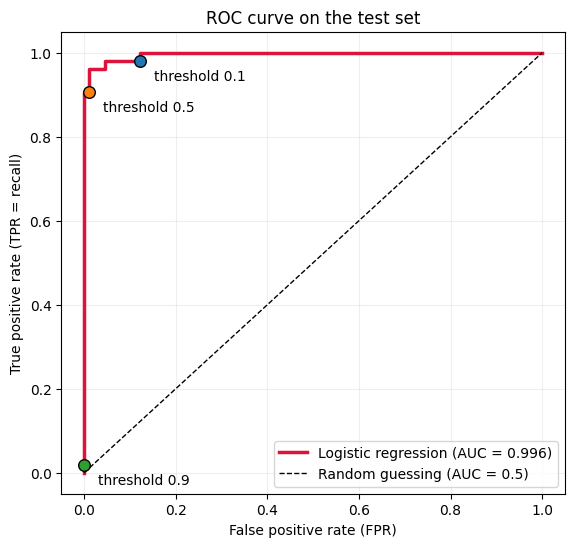

In [16]:
fpr, tpr, thresholds = roc_curve(yc_test, yc_proba)
auc = roc_auc_score(yc_test, yc_proba)

plt.figure(figsize=(6.5, 6))
plt.plot(fpr, tpr, linewidth=2.5, color="crimson", label=f"Logistic regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random guessing (AUC = 0.5)")

for t in (0.1, 0.5, 0.9):
    i = np.argmin(np.abs(thresholds - t))
    plt.scatter(fpr[i], tpr[i], s=70, zorder=3, edgecolor="black")
    plt.annotate(f"threshold {t}", (fpr[i], tpr[i]), xytext=(10, -14), textcoords="offset points")

plt.xlabel("False positive rate (FPR)")
plt.ylabel("True positive rate (TPR = recall)")
plt.title("ROC curve on the test set")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()

**Questions:**

1. What would a point in the top-left corner of the ROC curve mean?
2. If the AUC were 0.5, what would that tell you about the model?
3. Does the AUC depend on the 0.5 threshold? Does accuracy?

## 6. Why accuracy alone can be misleading

Suppose only 5% of observations are positive (fraud, a rare disease, a machine failure). A model that **always predicts the majority class** is 95% accurate and finds **nothing**. We compare such a "do-nothing" baseline with logistic regression on a generated dataset with 5% positives.

In [17]:
X_imb, y_imb = make_classification(
    n_samples=6000,
    n_features=6,
    n_informative=3,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.95, 0.05],
    class_sep=1.0,
    flip_y=0.01,
    random_state=RANDOM_STATE,
)

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_imb, y_imb, test_size=0.25, random_state=RANDOM_STATE, stratify=y_imb,
)

print("Class counts (train):", class_counts(yi_train))
print("Class counts (test): ", class_counts(yi_test))

Class counts (train): {0: 4254, 1: 246}
Class counts (test):  {0: 1418, 1: 82}


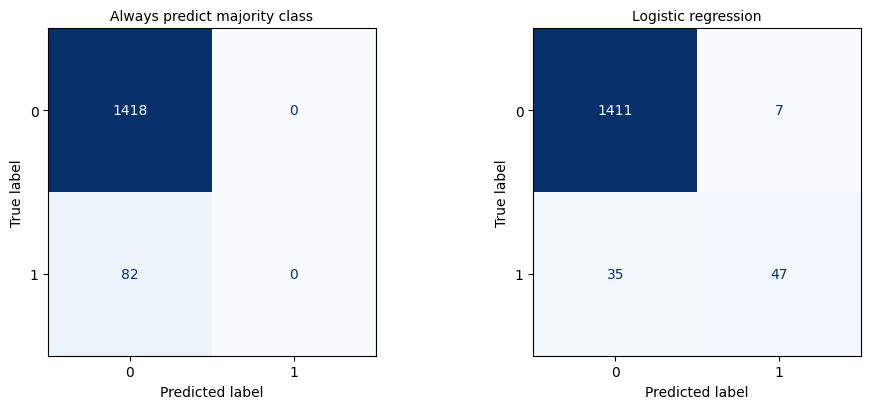

,accuracy,precision,recall,F1,ROC AUC
Always predict majority class,0.945,0.00,0.000,0.000,0.500
Logistic regression,0.972,0.87,0.573,0.691,0.966


In [18]:
imbalance_models = {
    "Always predict majority class": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}

results = {}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

for ax, (name, model) in zip(axes, imbalance_models.items()):
    model.fit(Xi_train, yi_train)
    pred = model.predict(Xi_test)
    proba = model.predict_proba(Xi_test)[:, 1]

    results[name] = {
        "accuracy": accuracy_score(yi_test, pred),
        "precision": precision_score(yi_test, pred, zero_division=0),
        "recall": recall_score(yi_test, pred),
        "F1": f1_score(yi_test, pred),
        "ROC AUC": roc_auc_score(yi_test, proba),
    }
    ConfusionMatrixDisplay.from_predictions(
        yi_test, pred, labels=[0, 1], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)

plt.tight_layout()
plt.show()

pd.DataFrame(results).T.round(3)

The do-nothing baseline has high **accuracy** but **zero recall**, and its AUC of 0.5 correctly says it has no ability to separate the classes. Logistic regression has similar accuracy, but its recall and AUC show that it actually finds positives.

Its recall at the default 0.5 threshold is still modest. Because positives are rare, the model rarely reaches 50% confidence. Lowering the threshold (Section 5.3) is the usual remedy — you will do exactly this in the assignment.

> **Practical lesson.** On imbalanced data, report precision, recall and AUC next to accuracy, and always compare against a trivial baseline.

## 7. Comparison with the perceptron

Both models learn a straight-line boundary. They differ in what they give back:

| | Perceptron | Logistic regression |
|---|---|---|
| Output | a class | a probability (and a class) |
| `predict_proba` | not available | available |
| Choosing a threshold | not natural | natural |
| Data that cannot be separated | never stops making mistakes | still finds a good boundary |

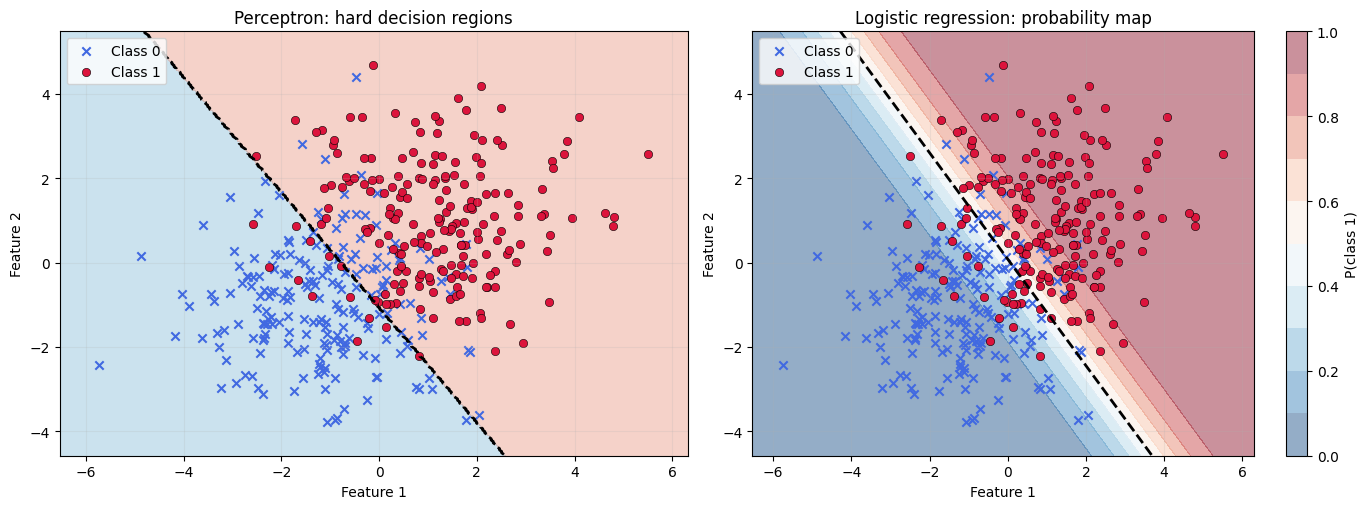

Perceptron test accuracy:          0.81
Logistic regression test accuracy: 0.84


In [19]:
perceptron_toy = Perceptron(max_iter=1000, tol=1e-3, eta0=0.1, random_state=RANDOM_STATE)
perceptron_toy.fit(Xt_train, yt_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
plot_decision_regions(perceptron_toy, X_toy, y_toy, "Perceptron: hard decision regions",
                      ax=axes[0], probabilistic=False)
plot_decision_regions(toy_model, X_toy, y_toy, "Logistic regression: probability map",
                      ax=axes[1], probabilistic=True)
plt.tight_layout()
plt.show()

print("Perceptron test accuracy:         ", round(perceptron_toy.score(Xt_test, yt_test), 3))
print("Logistic regression test accuracy:", round(toy_model.score(Xt_test, yt_test), 3))

**Question:** The two boundaries look similar. What extra information does logistic regression give you that the perceptron does not?

## 8. Summary and common pitfalls

| Concept | Key idea |
|---|---|
| Sigmoid | turns a linear score into a probability between 0 and 1 |
| Training | adjust weights to reduce log-loss (`.fit()` does this for us) |
| Threshold | the probability cut-off for predicting class 1; 0.5 is only a default |
| Confusion matrix | counts of TP, FP, FN, TN |
| Precision / recall / F1 | quality of positive predictions / coverage of real positives / balance of the two |
| ROC AUC | how well the model separates the classes across all thresholds |

**Common pitfalls**

1. Reporting only accuracy on imbalanced data.
2. Forgetting which class is the "positive" one.
3. Using test data to fit the scaler or to choose the threshold (use a pipeline and a validation set).
4. Ignoring a `ConvergenceWarning` instead of scaling the features or raising `max_iter`.

---
# Part 2 — Practice exercise (in class, ~30 minutes)

**Goal:** run the complete workflow yourself on a new dataset.

**Dataset:** the Wine dataset (178 wines, 13 chemical measurements, 3 cultivars). We turn it into a binary problem:

- **Positive class ($y=1$):** cultivar 1
- **Negative class ($y=0$):** the other two cultivars

Fill in each cell marked `# TODO`, then run the check cell below it. Work top to bottom — later exercises reuse earlier variables.

In [20]:
wine = load_wine()
X_wine = wine.data
y_wine = (wine.target == 1).astype(int)

print("Feature matrix shape:", X_wine.shape)
print("Class counts (1 = cultivar 1):", class_counts(y_wine))


def check(condition, message):
    print(("✅ " if condition else "❌ ") + message)

Feature matrix shape: (178, 13)
Class counts (1 = cultivar 1): {0: 107, 1: 71}


### Exercise 1 — Split the data

Create a stratified train/test split with `test_size=0.25` and `random_state=RANDOM_STATE`. Store the results in `Xw_train, Xw_test, yw_train, yw_test`.

In [21]:
# TODO: split X_wine, y_wine
Xw_train = Xw_test = yw_train = yw_test = None

In [ ]:
check(Xw_train is not None and Xw_test.shape[0] == 45, "Test set has 45 observations")
check(Xw_train is not None and abs(yw_train.mean() - yw_test.mean()) < 0.03,
      "Class proportions are similar in train and test")

### Exercise 2 — Train logistic regression

Build a pipeline with `StandardScaler` and `LogisticRegression(max_iter=1000)`, fit it on the training data, and store:

- `wine_model` — the fitted pipeline
- `yw_pred` — predicted classes for the test set
- `yw_proba` — predicted probability of class 1 for the test set

In [ ]:
# TODO
wine_model = None
yw_pred = None
yw_proba = None

In [ ]:
check(wine_model is not None and hasattr(wine_model, "predict_proba"), "wine_model is a fitted model")
check(yw_proba is not None and yw_proba.shape == (45,), "yw_proba has shape (45,)")
check(yw_pred is not None and accuracy_score(yw_test, yw_pred) > 0.85, "Test accuracy is above 0.85")

### Exercise 3 — Confusion matrix and metrics by hand

1. Get `tn, fp, fn, tp` from `confusion_matrix(..., labels=[0, 1]).ravel()`.
2. Compute `precision_w` and `recall_w` **from those four numbers** (not with `precision_score` / `recall_score`).
3. Show the confusion matrix with `ConfusionMatrixDisplay`.

In [ ]:
# TODO
tn = fp = fn = tp = None
precision_w = recall_w = None

In [ ]:
ok = tp is not None
check(ok and tn + fp + fn + tp == 45, "The four counts add up to 45")
check(ok and np.isclose(precision_w, precision_score(yw_test, yw_pred)), "Precision matches scikit-learn")
check(ok and np.isclose(recall_w, recall_score(yw_test, yw_pred)), "Recall matches scikit-learn")

### Exercise 4 — ROC curve and AUC

Compute `fpr_w, tpr_w, _` with `roc_curve`, compute `auc_w` with `roc_auc_score`, and plot the ROC curve with the random-guessing diagonal. Label both axes and show the AUC in the legend.

In [ ]:
# TODO
auc_w = None

In [ ]:
check(auc_w is not None and np.isclose(auc_w, roc_auc_score(yw_test, yw_proba)), "AUC is correct")
check(auc_w is not None and auc_w > 0.9, "AUC is above 0.9")

### Exercise 5 — Change the threshold

Compute predictions at a **low** threshold (0.2) and a **high** threshold (0.8) using `yw_proba`, then store the recall and precision for each:

`recall_low, precision_low` (threshold 0.2) and `recall_high, precision_high` (threshold 0.8).

In [ ]:
# TODO
recall_low = precision_low = recall_high = precision_high = None

In [ ]:
ok = recall_low is not None
check(ok and np.isclose(recall_low, recall_score(yw_test, yw_proba >= 0.2)), "Low-threshold recall is correct")
check(ok and np.isclose(precision_high, precision_score(yw_test, yw_proba >= 0.8, zero_division=0)),
      "High-threshold precision is correct")
check(ok and recall_low >= recall_high, "Lower threshold gives recall at least as high as the higher threshold")

### Exercise 6 — Interpret (1–2 sentences each)

1. What did the confusion matrix show that accuracy alone did not?
2. What happened to recall and precision when you lowered the threshold? Why?
3. Is this dataset imbalanced? Is accuracy trustworthy here? Use the class counts to justify.

**Your answers:**

1.
2.
3.